In [51]:
import pandas as pd
df = pd.read_csv('Insurance claims data.csv')

In [52]:
df.head()

,policy_id,subscription_length,vehicle_age,customer_age,region_code,region_density,segment,model,fuel_type,max_torque,max_power,engine_type,airbags,is_esc,is_adjustable_steering,is_tpms,is_parking_sensors,is_parking_camera,rear_brakes_type,displacement,cylinder,transmission_type,steering_type,turning_radius,length,width,gross_weight,is_front_fog_lights,is_rear_window_wiper,is_rear_window_washer,is_rear_window_defogger,is_brake_assist,is_power_door_locks,is_central_locking,is_power_steering,is_driver_seat_height_adjustable,is_day_night_rear_view_mirror,is_ecw,is_speed_alert,ncap_rating,claim_status
0,POL045360,9.3,1.2,41,C8,8794,C2,M4,Diesel,250Nm@2750rpm,113.45bhp@4000rpm,1.5 L U2 CRDi,6,Yes,Yes,Yes,Yes,Yes,Disc,1493,4,Automatic,Power,5.2,4300,1790,1720,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Yes,No,Yes,Yes,3,0
1,POL016745,8.2,1.8,35,C2,27003,C1,M9,Diesel,200Nm@1750rpm,97.89bhp@3600rpm,i-DTEC,2,No,Yes,No,Yes,Yes,Drum,1498,4,Manual,Electric,4.9,3995,1695,1051,Yes,No,No,Yes,No,Yes,Yes,Yes,Yes,Yes,Yes,Yes,4,0
2,POL007194,9.5,0.2,44,C8,8794,C2,M4,Diesel,250Nm@2750rpm,113.45bhp@4000rpm,1.5 L U2 CRDi,6,Yes,Yes,Yes,Yes,Yes,Disc,1493,4,Automatic,Power,5.2,4300,1790,1720,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Yes,No,Yes,Yes,3,0
3,POL018146,5.2,0.4,44,C10,73430,A,M1,CNG,60Nm@3500rpm,40.36bhp@6000rpm,F8D Petrol Engine,2,No,No,No,Yes,No,Drum,796,3,Manual,Power,4.6,3445,1515,1185,No,No,No,No,No,No,No,Yes,No,No,No,Yes,0,0
4,POL049011,10.1,1.0,56,C13,5410,B2,M5,Diesel,200Nm@3000rpm,88.77bhp@4000rpm,1.5 Turbocharged Revotorq,2,No,Yes,No,Yes,No,Drum,1497,4,Manual,Electric,5.0,3990,1755,1490,No,No,No,No,No,Yes,Yes,Yes,No,No,Yes,Yes,5,0


In [53]:
from IPython.display import display, display_html

display_html("<h3>1. Dataset Overview</h3>", raw=True)
print("Rows", df.shape[0])
print("Columns", df.shape[1])
print("Duplicate rows", df.duplicated().sum())


1. Dataset Overview

Rows 58592
Columns 41
Duplicate rows 0


In [54]:
display_html("<h3>2. Missing Value Checks</h3>", raw=True)
missing = df.isnull().sum()
missing = missing[missing>0]

if missing.empty:
    print("No missing value")
else:
    display(missing)

2. Missing Value Checks

No missing value


In [55]:
display_html("<h3>3. Policy ID Uniqueness</h3>", raw=True)
duplicates = df[df["policy_id"].duplicated(keep=False)]

if duplicates.empty:
    print("No duplicate")
else:
    display(duplicates)

3. Policy ID Uniqueness

No duplicate


In [56]:
display_html("<h3>4. Categorical Accuracy Checks</h3>", raw=True)

expected_catergories= {
    "fuel_type": ["Petrol", "Diesel","CNG"],
    "transmission_type": ["Manual", "Automatic"],
    "rear_brakes_type": ["Drum", "Disc"],
    "steering_type": ["Power", "Electric", "Manual"],
    "claim_status" : [0, 1],
}

for column, expected in expected_catergories.items():
    invalid = ~df[column].isin(expected)
    
    if invalid.sum() ==0:  
        print("Pass")

    else:
        display(df.loc[invalid, [column]].drop_duplicates())

4. Categorical Accuracy Checks

Pass
Pass
Pass
Pass
Pass


In [57]:
display_html("<h3>5. Boolean Consistency Checks</h3>", raw=True)

boolean_columns = [ c for c in df.columns if c.startswith("is_")]

for column in boolean_columns:
    invalid = ~df[column].isin(["Yes", "No"])

    if invalid.sum() == 0:
        print(f"PASS: {column}")
    else:
        print(f"FAIL: {column}")
        display(df.loc[invalid, [column]].drop_duplicates())

5. Boolean Consistency Checks

PASS: is_esc
PASS: is_adjustable_steering
PASS: is_tpms
PASS: is_parking_sensors
PASS: is_parking_camera
PASS: is_front_fog_lights
PASS: is_rear_window_wiper
PASS: is_rear_window_washer
PASS: is_rear_window_defogger
PASS: is_brake_assist
PASS: is_power_door_locks
PASS: is_central_locking
PASS: is_power_steering
PASS: is_driver_seat_height_adjustable
PASS: is_day_night_rear_view_mirror
PASS: is_ecw
PASS: is_speed_alert


In [58]:
display_html("<h3>6. Numeric Range Checks</h3>", raw=True)

range_checks = {
    "subscription_length": (0, 14),
    "vehicle_age": (0, 30),
    "customer_age": (18, 100),
    "airbags": (1, 6),
    "cylinder": (1, 12),
    "ncap_rating": (0, 5),
    "claim_status": (0, 1),
}

for column, (minimum, maximum) in range_checks.items():

    numeric_values = pd.to_numeric(df[column], errors="coerce")

    non_numeric = df[column].notna() & numeric_values.isna()

    invalid_range = (
        numeric_values.notna()
        & ~numeric_values.between(minimum, maximum)
    )

    if not non_numeric.any() and not invalid_range.any():
        print(f"PASS: {column}")
    else:
        print(f"FAIL: {column}")

        if non_numeric.any():
            print("Non-numeric values found:")
            display(df.loc[non_numeric, [column]].drop_duplicates())

        if invalid_range.any():
            print("Values outside the expected range:")
            display(df.loc[invalid_range, [column]].head(10))

6. Numeric Range Checks

PASS: subscription_length
PASS: vehicle_age
PASS: customer_age
PASS: airbags
PASS: cylinder
PASS: ncap_rating
PASS: claim_status


In [59]:
display_html("<h3>7. Policy ID Format Check</h3>", raw=True)

invalid_id = ~df["policy_id"].astype(str).str.fullmatch(r"POL\d+")

if invalid_id.sum() == 0:
    print("PASS: All policy IDs follow the expected format.")
else:
    print("FAIL: Invalid policy IDs found.")
    display(df.loc[invalid_id, ["policy_id"]].head(10))


7. Policy ID Format Check

PASS: All policy IDs follow the expected format.


In [60]:
display_html("<h3>8. Overall Data Quality Summary</h3>", raw=True)

print("Total missing cells:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate policy IDs:", df["policy_id"].duplicated().sum())
print("Claim status distribution:")
print(df["claim_status"].value_counts())

8. Overall Data Quality Summary

Total missing cells: 0
Duplicate rows: 0
Duplicate policy IDs: 0
Claim status distribution:
claim_status
0    54844
1     3748
Name: count, dtype: int64


In [61]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=["claim_status", "policy_id"], errors="ignore")
Y = pd.to_numeric(df["claim_status"], errors="coerce")
valid_rows = Y.isin([0, 1])

X = X.loc[valid_rows].copy()
Y = Y.loc[valid_rows].astype(int)

X_train, X_test, Y_train, Y_test = train_test_split(
    X,
    Y,
    test_size= 0.2,
    random_state= 42,
    stratify= y
)

print(f"Training features", X_train.shape)
print(f"Testing features", X_test.shape)
print(f"Training target", Y_train.shape)
print(f"Testing target", Y_test.shape)

Training features (46873, 39)
Testing features (11719, 39)
Training target (46873,)
Testing target (11719,)


In [68]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression

numeric_columns= X_train.select_dtypes(
    include=("number")
).columns.tolist()

categorical_columns= X_train.select_dtypes(
    include=("object", "string", "bool", "category")
).columns.tolist()

numeric_pipeline= Pipeline([
    ("imputer", SimpleImputer(strategy= "median")),
    ("scaler", StandardScaler())
])

categorical_pipeline= Pipeline([
    ("imputer", SimpleImputer(strategy= "most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown= "ignore"))
])

preprocessor= ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_columns),
    ("categorical", categorical_pipeline, categorical_columns)
])

model= Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter = 1000,
        class_weight = "balanced",
        random_state = 42
    ))
])

model.fit(X_train, Y_train)
print("Model trained")



Model trained


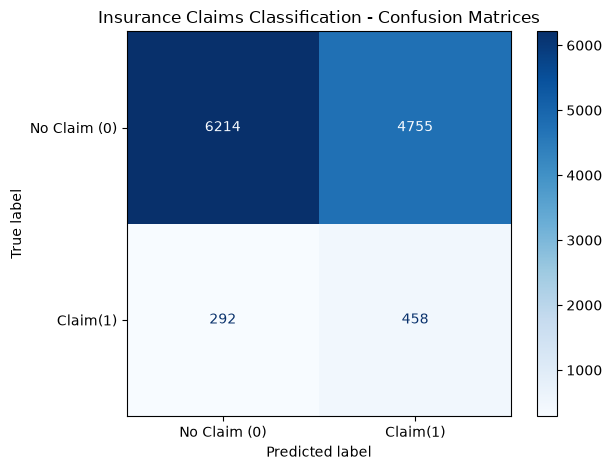


Classification Report:
              precision    recall  f1-score   support

No Claim (0)       0.96      0.57      0.71     10969
    Claim(1)       0.09      0.61      0.15       750

    accuracy                           0.57     11719
   macro avg       0.52      0.59      0.43     11719
weighted avg       0.90      0.57      0.68     11719


Actual vs Predicted Results (First 10 Records):


,actual claim_status,predicted claim_status
38212,0,1
3601,0,0
32008,0,0
20537,0,1
55345,0,0
42579,0,0
9780,0,1
14157,0,1
21157,0,1
36915,0,0


In [71]:
import matplotlib.pyplot as plt
from sklearn.metrics import(
    ConfusionMatrixDisplay,
    classification_report,
    accuracy_score
)

Y_pred = model.predict(X_test)

ConfusionMatrixDisplay.from_predictions(
    Y_test,
    Y_pred,
    labels= [0,1],
    display_labels= ["No Claim (0)", "Claim(1)"],
    cmap= "Blues"
)

plt.title("Insurance Claims Classification - Confusion Matrices")
plt.tight_layout()
plt.show()

print("\nClassification Report:")
print(
    classification_report(
        Y_test,
        Y_pred,
        labels= [0,1],
        target_names= ("No Claim (0)", "Claim(1)"),
        zero_division= 0
    )
)

comparison= pd.DataFrame({
    "actual claim_status": Y_test,
    "predicted claim_status": Y_pred,
}
)

print("\nActual vs Predicted Results (First 10 Records):")
display(comparison.head(10))

In [ ]:
import streamlit as st
import pandas as pd

st.title("📊 Insurance Claims Dashboard")
st.subheader("Actual vs Predicted Results")